# Seções que mudaram de local entre o 1º e o 2º turno de 2026

O TSE republicou `eleitorado_local_votacao_2026` em 23/10/2026 já com o 2º turno
(`NR_TURNO = 2`). Este notebook compara, seção por seção, o local de votação do
1º turno com o do 2º e responde duas perguntas:

1. **Qual candidato teve mais voto no 1º turno nas seções que mudaram de local**,
   em comparação com todas as seções do Brasil e com as demais seções dos mesmos
   municípios (para separar o efeito da geografia);
2. **Onde essas seções estão concentradas** (região, UF, município, zona).

O arquivo novo foi baixado com outro nome, para não sobrescrever o de 05/10 (só
1º turno) usado pela etapa 01:

```bash
curl -A "Mozilla/5.0" -o dados/01_bruto/2026/eleitorado_local_votacao_2026_t2.zip \
  https://cdn.tse.jus.br/estatistica/sead/odsele/eleitorado_locais_votacao/eleitorado_local_votacao_2026.zip
```

Os votos do 1º turno vêm de `votacao_secao_2026_BR.csv` e
`detalhe_votacao_secao_2026_BR.csv` (já extraídos em `dados/01_bruto/2026/`).
Uma seção que muda de local leva os mesmos eleitores para outro prédio, então o
voto da seção no 1º turno descreve quem foi afetado pela mudança.

**Duas definições do local do 1º turno.** O arquivo de 23/10 reescreveu o local
do 1º turno de ~400 seções em relação ao arquivo de 05/10 (gerado um dia depois
da votação). Na maioria, o T1 novo ficou igual ao T2, e a mudança deixa de
aparecer dentro do arquivo novo. Não dá para saber, só com esses arquivos, se é
correção do que aconteceu no 1º turno ou mudança posterior gravada nos dois turnos
(seção 2). Por isso tudo é calculado com as duas:

- **A**: T1 e T2 do arquivo de 23/10;
- **B**: T1 do arquivo de 05/10 × T2 do arquivo de 23/10.

In [1]:
import sys
import zipfile
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ / "src"))

from eleicoes import fontes  # noqa: E402
from eleicoes.config import (  # noqa: E402
    BRUTO_DIR,
    CODIGO_BRANCO,
    CODIGO_NULO,
    CODIGOS_NAO_CANDIDATO,
    CRS_METRICO_BR,
    GEOMETRIAS_DIR,
    NOME_BOLSONARO_POR_ANO,
    NOME_PT_POR_ANO,
    NR_BOLSONARO_POR_ANO,
    NR_PT,
    PROCESSADO_DIR,
)
from eleicoes.cores import COR_OUTROS_PARTIDOS, RAMPA_BOLSONARO, RAMPA_PT  # noqa: E402

ANO = 2026
NR_FLAVIO = NR_BOLSONARO_POR_ANO[ANO]
NOME_LULA = NOME_PT_POR_ANO[ANO]
NOME_FLAVIO = NOME_BOLSONARO_POR_ANO[ANO]

ZIP_23_10 = BRUTO_DIR / "2026" / "eleitorado_local_votacao_2026_t2.zip"
ZIP_05_10 = BRUTO_DIR / "2026" / "eleitorado_local_votacao_2026.zip"
CSV_VOTOS = BRUTO_DIR / "2026" / "votacao_secao_2026_BR.csv"
CSV_DETALHE = BRUTO_DIR / "2026" / "detalhe_votacao_secao_2026_BR.csv"
SAIDA = PROCESSADO_DIR / "aux"

# total oficial do 1º turno (ver CLAUDE.md, 05/10/2026)
OFICIAL_T1 = {NR_PT: 53_879_538, NR_FLAVIO: 56_104_503}

# abaixo disso, local do T1 e do T2 são tratados como o mesmo prédio renumerado
DIST_MESMO_PREDIO_M = 100
TIPOS_ESPECIAIS = ["Voto em trânsito", "Preso provisório"]

DEF_A = "A: T1 e T2 de 23/10"
DEF_B = "B: T1 de 05/10 × T2 de 23/10"

REGIAO = {"1": "Norte", "2": "Nordeste", "3": "Sudeste", "4": "Sul", "5": "Centro-Oeste"}
COR_CANDIDATO = {NOME_LULA: RAMPA_PT[2], NOME_FLAVIO: RAMPA_BOLSONARO[2]}

pd.set_option("display.max_colwidth", 50)
pd.set_option("display.width", 200)

## 1. Leitura do eleitorado por seção

Mesmas chaves da etapa 01 (`01_locais_votacao.qmd`): `id_local` e `id_secao` com
zona e número em 4 dígitos; a seção agregada vai para o local da seção principal
**do mesmo turno**.

In [2]:
COLUNAS = [
    "DT_GERACAO", "NR_TURNO", "SG_UF", "CD_MUNICIPIO", "NM_MUNICIPIO", "NR_ZONA", "NR_SECAO",
    "DS_TIPO_SECAO_AGREGADA", "NR_SECAO_PRINCIPAL", "NR_LOCAL_VOTACAO", "NM_LOCAL_VOTACAO",
    "DS_TIPO_LOCAL", "DS_ENDERECO", "NM_BAIRRO", "NR_LATITUDE", "NR_LONGITUDE",
    "QT_ELEITOR_SECAO", "NR_LOCAL_VOTACAO_ORIGINAL",
]
crosswalk = pd.read_parquet(PROCESSADO_DIR / "aux" / "crosswalk_mun_tse_ibge.parquet", columns=["cd_mun_tse", "cd_mun"])


def chave(cd_mun: pd.Series, zona: pd.Series, numero: pd.Series) -> pd.Series:
    return cd_mun + zona.str.zfill(4) + numero.str.zfill(4)


def le_eleitorado(caminho_zip: Path) -> pd.DataFrame:
    with zipfile.ZipFile(caminho_zip) as z:
        nome_csv = next(n for n in z.namelist() if n.endswith("_BRASIL.csv"))
        df = pd.read_csv(z.open(nome_csv), sep=";", encoding="latin-1", dtype=str, usecols=COLUNAS)
    df.columns = df.columns.str.lower()
    df["nr_turno"] = df["nr_turno"].astype(int)
    df["qt_eleitor_secao"] = df["qt_eleitor_secao"].astype(int)
    df["id_secao"] = chave(df["cd_municipio"], df["nr_zona"], df["nr_secao"])
    df["id_local_proprio"] = chave(df["cd_municipio"], df["nr_zona"], df["nr_local_votacao"])
    df["id_secao_principal"] = chave(df["cd_municipio"], df["nr_zona"], df["nr_secao_principal"]).where(
        df["nr_secao_principal"] != "-1"
    )
    assert not df.duplicated(["id_secao", "nr_turno"]).any()

    da_principal = df[["id_secao", "nr_turno", "id_local_proprio"]].rename(
        columns={"id_secao": "id_secao_principal", "id_local_proprio": "id_local_da_principal"}
    )
    df = df.merge(da_principal, on=["id_secao_principal", "nr_turno"], how="left")
    df["id_local"] = df["id_local_da_principal"].fillna(df["id_local_proprio"])
    return df.merge(crosswalk, left_on="cd_municipio", right_on="cd_mun_tse", how="left").drop(columns="cd_mun_tse")


novo = le_eleitorado(ZIP_23_10)
antigo = le_eleitorado(ZIP_05_10)
assert set(novo["nr_turno"]) == {1, 2}, "o arquivo ainda não traz o 2º turno"
pd.concat({"05/10": antigo, "23/10": novo}, names=["arquivo"]).groupby(["arquivo", "nr_turno"]).agg(
    geracao=("dt_geracao", "first"), secoes=("id_secao", "size"), eleitores=("qt_eleitor_secao", "sum"),
    locais=("id_local", "nunique"),
)

geracao  secoes  eleitores  locais
arquivo nr_turno                                       
05/10   1         05/10/2026  517179  158745463   94299
23/10   1         23/10/2026  517179  158745463   94268
        2         23/10/2026  517179  158745463   94259

Cadastro de cada local, a partir das linhas do próprio local (a linha de uma
agregada pode trazer outro prédio). A coordenada vem da camada
`geom_locais_votacao_2026` (validada na etapa 02) quando o local está lá; senão,
a do TSE, com vírgula decimal. O TSE ainda não tem coordenada (`-1`) para a maior
parte dos locais criados para o 2º turno.

In [3]:
geom_locais = gpd.read_file(GEOMETRIAS_DIR / "geom_locais_votacao_2026.gpkg")
geom_locais = geom_locais.loc[~geom_locais["flag_sem_coord"]].set_index("id_local").geometry


def cadastro(df: pd.DataFrame, turno: int) -> pd.DataFrame:
    cad = (
        df.loc[df["nr_turno"] == turno]
        .assign(principal=lambda d: d["ds_tipo_secao_agregada"] == "Principal")
        .sort_values("principal", ascending=False, kind="stable")
        .drop_duplicates("id_local_proprio")
        .drop(columns="id_local")
        .rename(columns={"id_local_proprio": "id_local"})
        .set_index("id_local")
    )
    lat = pd.to_numeric(cad["nr_latitude"].str.replace(",", ".", regex=False), errors="coerce")
    lon = pd.to_numeric(cad["nr_longitude"].str.replace(",", ".", regex=False), errors="coerce")
    valida = lat.between(-34, 6) & lon.between(-74, -28)
    ponto = gpd.GeoSeries(gpd.points_from_xy(lon.where(valida), lat.where(valida)), index=cad.index, crs=4674)
    validada = geom_locais.reindex(cad.index)
    cad["geometry"] = validada.where(validada.notna(), ponto)
    return cad[["nm_local_votacao", "ds_endereco", "nm_bairro", "ds_tipo_local", "geometry"]]

## 2. O 1º turno nos dois arquivos

Seções em que o local do 1º turno não é o mesmo nos arquivos de 05/10 e 23/10,
conforme o que o T2 de 23/10 diz.

In [4]:
def secoes_turno(df: pd.DataFrame, turno: int) -> pd.DataFrame:
    return df.loc[df["nr_turno"] == turno].set_index("id_secao")


t1_antigo, t1_novo, t2_novo = secoes_turno(antigo, 1), secoes_turno(novo, 1), secoes_turno(novo, 2)
assert t1_antigo.index.sort_values().equals(t1_novo.index.sort_values())

reescritas = pd.DataFrame({
    "t1_05_10": t1_antigo["id_local"], "t1_23_10": t1_novo["id_local"], "t2_23_10": t2_novo["id_local"],
}).loc[lambda d: d["t1_05_10"] != d["t1_23_10"]]
reescritas["caso"] = np.select(
    [reescritas["t1_23_10"] == reescritas["t2_23_10"], reescritas["t1_05_10"] == reescritas["t2_23_10"]],
    ["T1 novo = T2 (mudança some em A, aparece em B)", "T1 antigo = T2 (mudança aparece em A, some em B)"],
    default="os três diferentes",
)
locais_05_10 = set(antigo["id_local_proprio"])
reescritas["local T1 novo já existia em 05/10"] = reescritas["t1_23_10"].isin(locais_05_10)
reescritas.groupby(["caso", "local T1 novo já existia em 05/10"]).size()

caso                                              local T1 novo já existia em 05/10
T1 antigo = T2 (mudança aparece em A, some em B)  False                                 21
T1 novo = T2 (mudança some em A, aparece em B)    False                                261
                                                  True                                 161
dtype: int64

Exemplo do segundo caso: Laranjeiras do Sul (PR), zona 45. Em 05/10 o 1º turno
era no Colégio Estadual Gildo Aluisio Schuck; em 23/10 o 1º turno passou a ser no
Pavilhão da Igreja Matriz Santana (local que não existia no arquivo de 05/10) e o
2º turno volta ao colégio. Isso sugere que o arquivo novo corrige o 1º turno com
o que aconteceu de fato, o que favorece a definição A — mas não prova nada sobre
as demais seções reescritas.

In [5]:
c_antigo_t1, c_novo_t1, c_novo_t2 = cadastro(antigo, 1), cadastro(novo, 1), cadastro(novo, 2)
exemplo = reescritas.loc[reescritas.index.str.startswith("765970045")].head(1)
pd.DataFrame({
    "T1 de 05/10": c_antigo_t1.loc[exemplo["t1_05_10"], "nm_local_votacao"].to_numpy(),
    "T1 de 23/10": c_novo_t1.loc[exemplo["t1_23_10"], "nm_local_votacao"].to_numpy(),
    "T2 de 23/10": c_novo_t2.loc[exemplo["t2_23_10"], "nm_local_votacao"].to_numpy(),
})

,T1 de 05/10,T1 de 23/10,T2 de 23/10
0,COLEGIO ESTADUAL PROFESSOR GILDO ALUISIO SCHUCK,PAVILHÃO DA IGREJA MATRIZ SANTANA,COLEGIO ESTADUAL PROFESSOR GILDO ALUISIO SCHUCK


## 3. Local do 1º turno × local do 2º, por seção

Para cada seção que mudou: nomes, endereços e distância em linha reta entre os
dois prédios. Distância abaixo de 100 m, ou mesmo nome e endereço, é tratada
como **renumeração** (o prédio é o mesmo); seção de local especial (voto em
trânsito, preso provisório) fica à parte; o resto é **troca de prédio**, o
critério de "mudou" daqui em diante.

In [6]:
def normaliza(s: pd.Series) -> pd.Series:
    return s.fillna("").str.upper().str.replace(r"\W+", " ", regex=True).str.strip()


def compara(t1: pd.DataFrame, cad_t1: pd.DataFrame, t2: pd.DataFrame, cad_t2: pd.DataFrame) -> pd.DataFrame:
    sec = t1[["sg_uf", "cd_municipio", "cd_mun", "nm_municipio", "nr_zona", "nr_secao", "ds_tipo_secao_agregada",
              "qt_eleitor_secao", "id_local"]].rename(columns={"id_local": "local_t1"})
    sec["local_t2"] = t2["id_local"].reindex(sec.index)
    sec["mudou_local"] = sec["local_t1"] != sec["local_t2"]

    m = sec.loc[sec["mudou_local"]]
    a = cad_t1.reindex(m["local_t1"]).set_index(m.index)
    b = cad_t2.reindex(m["local_t2"]).set_index(m.index)
    dist = (gpd.GeoSeries(a["geometry"], crs=4674).to_crs(CRS_METRICO_BR)
            .distance(gpd.GeoSeries(b["geometry"], crs=4674).to_crs(CRS_METRICO_BR)))
    mesmo_predio = (dist < DIST_MESMO_PREDIO_M) | (
        (normaliza(a["nm_local_votacao"]) == normaliza(b["nm_local_votacao"]))
        & (normaliza(a["ds_endereco"]) == normaliza(b["ds_endereco"]))
    )
    tipo = pd.Series(np.where(mesmo_predio, "renumeração", "troca de prédio"), index=m.index)
    tipo[a["ds_tipo_local"].isin(TIPOS_ESPECIAIS) | b["ds_tipo_local"].isin(TIPOS_ESPECIAIS)] = "local especial"

    sec["tipo_mudanca"] = tipo.reindex(sec.index).fillna("mesmo local")
    sec["dist_m"] = dist.reindex(sec.index)
    for col in ["nm_local_votacao", "ds_endereco", "nm_bairro", "ds_tipo_local"]:
        sec[f"{col}_t1"] = a[col].reindex(sec.index)
        sec[f"{col}_t2"] = b[col].reindex(sec.index)
    sec["mudou"] = sec["tipo_mudanca"] == "troca de prédio"
    sec["regiao"] = sec["cd_mun"].str[0].map(REGIAO).fillna("Exterior")
    return sec.reset_index()


DEFINICOES = {
    DEF_A: compara(t1_novo, c_novo_t1, t2_novo, c_novo_t2),
    DEF_B: compara(t1_antigo, c_antigo_t1, t2_novo, c_novo_t2),
}
pd.DataFrame({
    d: s.groupby("tipo_mudanca").agg(secoes=("id_secao", "size"), eleitores=("qt_eleitor_secao", "sum")).stack()
    for d, s in DEFINICOES.items()
}).unstack()

A: T1 e T2 de 23/10            B: T1 de 05/10 × T2 de 23/10           
                             secoes  eleitores                       secoes  eleitores
tipo_mudanca                                                                          
mesmo local                  516832  158644638                       516431  158544253
renumeração                      70      18749                           82      21818
troca de prédio                 277      82076                          666     179392

In [7]:
pd.DataFrame({
    d: s.loc[s["mudou"], "dist_m"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]) for d, s in DEFINICOES.items()
}).round(0)

,A: T1 e T2 de 23/10,B: T1 de 05/10 × T2 de 23/10
count,152.0,330.0
mean,883.0,1180.0
std,1507.0,2917.0
min,106.0,106.0
25%,284.0,272.0
50%,565.0,565.0
75%,1088.0,1088.0
90%,1190.0,1607.0
max,14422.0,27725.0


Em 2022 foram 1.387 seções com outro local no 2º turno (0,28%), sem separar
renumeração de troca de prédio.

## 4. Votos do 1º turno por seção

In [8]:
votos = fontes.ler_votacao_secao(CSV_VOTOS, ANO, 1, caminho_detalhe=CSV_DETALHE)
votos["id_secao"] = (
    votos["cd_mun_tse"] + votos["nr_zona"].astype(str).str.zfill(4) + votos["nr_secao"].astype(str).str.zfill(4)
)
nomes = (
    votos.loc[~votos["nr_votavel"].isin(CODIGOS_NAO_CANDIDATO)]
    .drop_duplicates("nr_votavel")
    .set_index("nr_votavel")["nm_votavel"]
    .str.title()
)
nomes[NR_PT], nomes[NR_FLAVIO] = NOME_LULA, NOME_FLAVIO

por_secao = votos.pivot_table(index="id_secao", columns="nr_votavel", values="qt_votos", aggfunc="sum", fill_value=0)
por_secao = por_secao.join(votos.groupby("id_secao")[["qt_comparecimento", "qt_aptos"]].first())
CANDIDATOS = [c for c in por_secao.columns if isinstance(c, (int, np.integer)) and c not in CODIGOS_NAO_CANDIDATO]
CANDIDATOS = sorted(CANDIDATOS, key=lambda c: -por_secao[c].sum())

assert por_secao.index.isin(t1_novo.index).all(), "seção com voto e sem linha no eleitorado"
BASES = {d: s.merge(por_secao, left_on="id_secao", right_index=True, how="inner") for d, s in DEFINICOES.items()}
pd.DataFrame({
    d: {"seções com voto": len(b), "que mudaram": b["mudou"].sum(),
        "que mudaram sem urna própria (agregadas)": DEFINICOES[d]["mudou"].sum() - b["mudou"].sum()}
    for d, b in BASES.items()
})

,A: T1 e T2 de 23/10,B: T1 de 05/10 × T2 de 23/10
seções com voto,499206,499206
que mudaram,259,610
que mudaram sem urna própria (agregadas),18,56


Seções agregadas não têm urna própria: o voto delas está na seção principal, que
vai para o mesmo local.

## 5. Quem teve mais voto onde mudou

Grupos (seções com voto):

- **mudou**: seção que trocou de prédio entre os turnos;
- **mesmos municípios, não mudou**: as demais seções dos municípios que tiveram
  alguma troca;
- **Brasil**: todas.

In [9]:
def resume(df: pd.DataFrame) -> pd.Series:
    tot = df[CANDIDATOS + [CODIGO_BRANCO, CODIGO_NULO, "qt_comparecimento", "qt_aptos"]].sum()
    validos = tot[CANDIDATOS].sum()
    linha = {
        "seções": len(df),
        "aptos": tot["qt_aptos"],
        "comparecimento": tot["qt_comparecimento"],
        "válidos": validos,
    }
    for c in CANDIDATOS:
        linha[f"votos {nomes[c]}"] = tot[c]
    linha |= {
        "% abstenção": 100 * (1 - tot["qt_comparecimento"] / tot["qt_aptos"]),
        "% brancos": 100 * tot[CODIGO_BRANCO] / tot["qt_comparecimento"],
        "% nulos": 100 * tot[CODIGO_NULO] / tot["qt_comparecimento"],
    }
    for c in CANDIDATOS:
        linha[f"% {nomes[c]}"] = 100 * tot[c] / validos
    return pd.Series(linha)


def resumo_grupos(base: pd.DataFrame) -> pd.DataFrame:
    mun = set(base.loc[base["mudou"], "cd_municipio"])
    grupos = {
        "mudou": base["mudou"],
        "mesmos municípios, não mudou": base["cd_municipio"].isin(mun) & ~base["mudou"],
        "Brasil": pd.Series(True, index=base.index),
    }
    r = pd.DataFrame({g: resume(base.loc[m]) for g, m in grupos.items()})
    r["mudou − Brasil (p.p.)"] = r["mudou"] - r["Brasil"]
    r["mudou − mesmos mun. (p.p.)"] = r["mudou"] - r["mesmos municípios, não mudou"]
    return r


RESUMOS = {d: resumo_grupos(b) for d, b in BASES.items()}
resumo = pd.concat(RESUMOS, axis=1, names=["definição", "grupo"])
contagens = ["seções", "aptos", "válidos"] + [f"votos {nomes[c]}" for c in CANDIDATOS[:2]]
resumo.loc[contagens, (slice(None), ["mudou", "mesmos municípios, não mudou", "Brasil"])].map("{:,.0f}".format)

definição              A: T1 e T2 de 23/10                                           B: T1 de 05/10 × T2 de 23/10                                          
grupo                                mudou mesmos municípios, não mudou       Brasil                        mudou mesmos municípios, não mudou       Brasil
seções                                 259                       51,029      499,206                          610                       60,485      499,206
aptos                               81,899                   17,887,945  158,745,007                      179,090                   20,748,785  158,745,007
válidos                             61,218                   12,976,223  119,306,034                      134,842                   15,141,441  119,306,034
votos Flávio Bolsonaro              26,116                    5,821,043   56,104,503                       54,122                    6,902,645   56,104,503
votos Lula                          31,198                    5,909,176   53,879,538                       72,785                    6,834,277   53,879,538

In [10]:
pcs = ["% abstenção", "% brancos", "% nulos"] + [f"% {nomes[c]}" for c in CANDIDATOS[:5]]
resumo.loc[pcs].round(2)

definição                           A: T1 e T2 de 23/10                                                                                      B: T1 de 05/10 × T2 de 23/10  \
grupo                                             mudou mesmos municípios, não mudou Brasil mudou − Brasil (p.p.) mudou − mesmos mun. (p.p.)                        mudou   
% abstenção                                       21.66                        23.24  21.08                  0.58                      -1.58                        21.25   
% brancos                                          1.57                         2.14   1.84                 -0.27                      -0.57                         1.56   
% nulos                                            3.01                         3.35   2.93                  0.08                      -0.33                         2.83   
% Flávio Bolsonaro                                42.66                        44.86  47.03                 -4.37                      -2.20                        40.14   
% Lula                                            50.96                        45.54  45.16                  5.80                       5.42                        53.98   
% Augusto Jorge Cury                               2.73                         3.43   2.89                 -0.16                      -0.69                         2.59   
% Renan Antonio Ferreira Dos Santos                1.69                         3.06   2.24                 -0.55                      -1.37                         1.54   
% Ronaldo Ramos Caiado                             1.59                         2.36   2.18                 -0.60                      -0.77                         1.40   

definição                                                                                                                 
grupo                               mesmos municípios, não mudou Brasil mudou − Brasil (p.p.) mudou − mesmos mun. (p.p.)  
% abstenção                                                22.89  21.08                  0.16                      -1.64  
% brancos                                                   2.10   1.84                 -0.28                      -0.54  
% nulos                                                     3.27   2.93                 -0.09                      -0.43  
% Flávio Bolsonaro                                         45.59  47.03                 -6.89                      -5.45  
% Lula                                                     45.14  45.16                  8.82                       8.84  
% Augusto Jorge Cury                                        3.35   2.89                 -0.31                      -0.76  
% Renan Antonio Ferreira Dos Santos                         2.93   2.24                 -0.71                      -1.39  
% Ronaldo Ramos Caiado                                      2.28   2.18                 -0.78                      -0.88

### Comparação município a município

O total do grupo "mudou" pode ser puxado por poucos municípios grandes. Aqui a
diferença (seções que mudaram − demais seções do mesmo município) é calculada
em cada município e depois resumida: média simples, média ponderada pelos
válidos das seções que mudaram, mediana e em quantos municípios o candidato foi
melhor nas seções que mudaram.

In [11]:
def pc_validos(df: pd.DataFrame) -> pd.DataFrame:
    v = df[CANDIDATOS].sum(axis=1)
    return pd.DataFrame({nomes[c]: 100 * df[c] / v for c in [NR_PT, NR_FLAVIO]}).assign(validos=v)


def compara_municipios(base: pd.DataFrame) -> pd.DataFrame:
    mun = set(base.loc[base["mudou"], "cd_municipio"])
    agg = base.loc[base["cd_municipio"].isin(mun)].groupby(["cd_municipio", "mudou"])[CANDIDATOS].sum()
    pc = pc_validos(agg).unstack("mudou")
    dif = pd.DataFrame({n: pc[(n, True)] - pc[(n, False)] for n in [NOME_LULA, NOME_FLAVIO]})
    dif["validos_mudou"] = pc[("validos", True)]
    dif = dif.dropna()  # município em que todas as seções mudaram não tem comparação
    return pd.DataFrame({
        n: {
            "municípios": len(dif),
            "média simples (p.p.)": dif[n].mean(),
            "média ponderada (p.p.)": np.average(dif[n], weights=dif["validos_mudou"]),
            "mediana (p.p.)": dif[n].median(),
            "municípios com % maior onde mudou": (dif[n] > 0).sum(),
        }
        for n in [NOME_LULA, NOME_FLAVIO]
    })


pd.concat({d: compara_municipios(b) for d, b in BASES.items()}, axis=1).round(2)

A: T1 e T2 de 23/10                  B: T1 de 05/10 × T2 de 23/10                 
                                                 Lula Flávio Bolsonaro                         Lula Flávio Bolsonaro
municípios                                      65.00            65.00                       129.00           129.00
média simples (p.p.)                             2.92            -2.40                         2.71            -2.29
média ponderada (p.p.)                          -0.52             0.56                         0.79            -0.68
mediana (p.p.)                                   0.21             0.30                         2.00            -1.18
municípios com % maior onde mudou               33.00            34.00                        75.00            56.00

### Mais votado por local

Em quantos locais do 1º turno que cederam seções cada candidato foi o mais votado
(só nas seções que mudaram), comparado com a mesma proporção entre todos os
locais do 1º turno.

In [12]:
def vencedor_por_local(df: pd.DataFrame) -> pd.Series:
    return df.groupby("local_t1")[CANDIDATOS].sum().idxmax(axis=1).map(nomes)


def vencedores(base: pd.DataFrame) -> pd.DataFrame:
    mudou = vencedor_por_local(base.loc[base["mudou"]]).value_counts()
    todos = vencedor_por_local(base).value_counts()
    return pd.DataFrame({
        "locais que mudaram": mudou,
        "% locais que mudaram": 100 * mudou / mudou.sum(),
        "% todos os locais": 100 * todos / todos.sum(),
    }).fillna(0).loc[lambda d: d["locais que mudaram"] > 0]


pd.concat({d: vencedores(b) for d, b in BASES.items()}, axis=1).round(1)

A: T1 e T2 de 23/10                                        B: T1 de 05/10 × T2 de 23/10                                       
                  locais que mudaram % locais que mudaram % todos os locais           locais que mudaram % locais que mudaram % todos os locais
Flávio Bolsonaro                25.0                 33.3              46.5                         48.0                 23.4              46.5
Lula                            50.0                 66.7              53.5                        157.0                 76.6              53.5

## 6. Onde estão as seções que trocaram de prédio

In [13]:
def concentracao(sec: pd.DataFrame, chaves: list[str]) -> pd.DataFrame:
    sec = sec.assign(eleitores_mudou=sec["qt_eleitor_secao"].where(sec["mudou"], 0))
    g = sec.groupby(chaves)
    t = pd.DataFrame({
        "seções": g.size(),
        "seções que mudaram": g["mudou"].sum(),
        "locais T1 que cederam seções": sec.loc[sec["mudou"]].groupby(chaves)["local_t1"].nunique(),
        "eleitores que mudaram": g["eleitores_mudou"].sum(),
        "eleitores": g["qt_eleitor_secao"].sum(),
    }).fillna(0)
    t["% seções"] = 100 * t["seções que mudaram"] / t["seções"]
    t["% eleitores"] = 100 * t["eleitores que mudaram"] / t["eleitores"]
    t["% do total que mudou"] = 100 * t["eleitores que mudaram"] / t["eleitores que mudaram"].sum()
    return t.sort_values("eleitores que mudaram", ascending=False)


COLS_CONC = ["seções que mudaram", "eleitores que mudaram", "% eleitores", "% do total que mudou"]
POR_UF = {d: concentracao(s, ["regiao", "sg_uf"]) for d, s in DEFINICOES.items()}
POR_MUN = {d: concentracao(s, ["sg_uf", "cd_municipio", "nm_municipio"]) for d, s in DEFINICOES.items()}
pd.concat({d: concentracao(s, ["regiao"])[COLS_CONC] for d, s in DEFINICOES.items()}, axis=1).round(2)

A: T1 e T2 de 23/10                                                        B: T1 de 05/10 × T2 de 23/10                                                       
              seções que mudaram eleitores que mudaram % eleitores % do total que mudou           seções que mudaram eleitores que mudaram % eleitores % do total que mudou
regiao                                                                                                                                                                     
Sudeste                       80                 25453        0.04                31.01                          228                 66842        0.10                37.26
Nordeste                      97                 24345        0.06                29.66                          246                 58999        0.14                32.89
Norte                         59                 19384        0.15                23.62                          131                 38490        0.29                21.46
Sul                           24                  7470        0.03                 9.10                           37                  9681        0.04                 5.40
Centro-Oeste                  17                  5424        0.05                 6.61                           24                  5380        0.04                 3.00
Exterior                       0                     0        0.00                 0.00                            0                     0        0.00                 0.00

In [14]:
pd.concat({d: t[COLS_CONC] for d, t in POR_UF.items()}, axis=1).fillna(0).loc[
    lambda d: d.filter(like="seções que mudaram").sum(axis=1) > 0
].sort_values((DEF_A, "eleitores que mudaram"), ascending=False).round(2)

A: T1 e T2 de 23/10                                                        B: T1 de 05/10 × T2 de 23/10                                                       
                    seções que mudaram eleitores que mudaram % eleitores % do total que mudou           seções que mudaram eleitores que mudaram % eleitores % do total que mudou
regiao       sg_uf                                                                                                                                                               
Sudeste      MG                     39                 12054        0.07                14.69                          139                 38019        0.23                21.19
Norte        PA                     32                  9486        0.15                11.56                           83                 22609        0.36                12.60
             AM                     21                  7920        0.28                 9.65                           32                 11562        0.41                 6.45
Sudeste      SP                     22                  7650        0.02                 9.32                           35                 11218        0.03                 6.25
Nordeste     PI                     24                  5701        0.21                 6.95                          127                 27376        1.01                15.26
Centro-Oeste MT                     17                  5424        0.21                 6.61                           24                  5380        0.20                 3.00
Nordeste     RN                     19                  5207        0.20                 6.34                           19                  5207        0.20                 2.90
             MA                     23                  4519        0.09                 5.51                           40                  9625        0.19                 5.37
Sul          PR                     13                  3993        0.05                 4.87                           16                  4054        0.05                 2.26
Sudeste      ES                     14                  3869        0.13                 4.71                           14                  3869        0.13                 2.16
Sul          RS                     11                  3477        0.04                 4.24                           21                  5627        0.07                 3.14
Nordeste     PE                      8                  2773        0.04                 3.38                           10                  3363        0.05                 1.87
             PB                      9                  2447        0.08                 2.98                            9                  2447        0.08                 1.36
             CE                     10                  2271        0.03                 2.77                           14                  3104        0.04                 1.73
Sudeste      RJ                      5                  1880        0.01                 2.29                           40                 13736        0.11                 7.66
Norte        AP                      5                  1716        0.30                 2.09                           13                  3675        0.64                 2.05
Nordeste     BA                      4                  1427        0.01                 1.74                           27                  7877        0.07                 4.39
Norte        RO                      1                   262        0.02                 0.32                            1                   262        0.02                 0.15
             TO                      0                     0        0.00                 0.00                            2                   382        0.03                 0.21

In [15]:
for d, t in POR_MUN.items():
    print(d)
    display(t.loc[t["seções que mudaram"] > 0].head(15).round(2))

A: T1 e T2 de 23/10


seções  seções que mudaram  locais T1 que cederam seções  eleitores que mudaram  eleitores  % seções  % eleitores  % do total que mudou
sg_uf cd_municipio nm_municipio                                                                                                                                                  
AM    02550        MANAUS                   4075                  16                           2.0                   6011    1472138      0.39         0.41                  7.32
SP    71072        SÃO PAULO               26696                  16                           2.0                   5405    9135407      0.06         0.06                  6.59
PR    76597        LARANJEIRAS DO SUL         85                  12                           1.0                   3777      24386     14.12        15.49                  4.60
MG    53970        UBÁ                       256                  11                           2.0                   3744      71685      4.30         5.22                  4.56
MT    90280        CONFRESA                   83                   8                           1.0                   2832      26085      9.64        10.86                  3.45
      90050        ALTO ARAGUAIA              46                   9                           1.0                   2592      11548     19.57        22.45                  3.16
PA    04138        ANAJÁS                     90                   8                           1.0                   2463      22688      8.89        10.86                  3.00
PI    10898        GUADALUPE                  37                   9                           2.0                   2460       8738     24.32        28.15                  3.00
MG    49395        PARACATU                  198                   7                           1.0                   2369      68444      3.54         3.46                  2.89
SP    70831        SÃO JOÃO DA BOA VISTA     202                   6                           1.0                   2245      67282      2.97         3.34                  2.74
PA    04090        ALMEIRIM                  117                   7                           2.0                   2070      23931      5.98         8.65                  2.52
ES    56502        IBITIRAMA                  28                   7                           1.0                   1912       7475     25.00        25.58                  2.33
RJ    60011        RIO DE JANEIRO          12809                   5                           1.0                   1880    4950429      0.04         0.04                  2.29
PA    04359        BREVES                    239                   5                           1.0                   1828      77425      2.09         2.36                  2.23
      04472        CASTANHAL                 468                   5                           1.0                   1806     143768      1.07         1.26                  2.20

B: T1 de 05/10 × T2 de 23/10


seções  seções que mudaram  locais T1 que cederam seções  eleitores que mudaram  eleitores  % seções  % eleitores  % do total que mudou
sg_uf cd_municipio nm_municipio                                                                                                                                                
RJ    59277        ARRAIAL DO CABO         111                  21                           3.0                   6933      35402     18.92        19.58                  3.86
AM    02550        MANAUS                 4075                  16                           2.0                   6011    1472138      0.39         0.41                  3.35
MG    40690        ARAGUARI                315                  23                           3.0                   5853      90389      7.30         6.48                  3.26
SP    71072        SÃO PAULO             26696                  17                           3.0                   5681    9135407      0.06         0.06                  3.17
RJ    58696        NOVA IGUAÇU            1916                  14                           1.0                   4923     615377      0.73         0.80                  2.74
MA    09571        SANTA INÊS              268                  13                           3.0                   4319      63577      4.85         6.79                  2.41
BA    39047        SERRA DO RAMALHO        103                  16                           4.0                   4288      26085     15.53        16.44                  2.39
MG    42676        CARATINGA               226                  14                           2.0                   4278      60549      6.19         7.07                  2.38
      53970        UBÁ                     256                  11                           2.0                   3744      71685      4.30         5.22                  2.09
      47031        JANUÁRIA                225                  18                          10.0                   3555      51369      8.00         6.92                  1.98
PI    10430        CAMPO MAIOR             189                  17                           3.0                   3550      35907      8.99         9.89                  1.98
PA    05630        VIGIA                   157                  16                           9.0                   3531      39713     10.19         8.89                  1.97
SP    69299        PRESIDENTE PRUDENTE     581                  12                           1.0                   3292     165352      2.07         1.99                  1.84
PI    10618        CRISTINO CASTRO          35                  11                           2.0                   3080       8625     31.43        35.71                  1.72
MT    90280        CONFRESA                 83                   8                           1.0                   2832      26085      9.64        10.86                  1.58

In [16]:
pd.concat(
    {d: concentracao(s, ["sg_uf", "nm_municipio", "nr_zona"]).head(10)[COLS_CONC] for d, s in DEFINICOES.items()}
).round(2)

seções que mudaram  eleitores que mudaram  % eleitores  % do total que mudou
                             sg_uf nm_municipio          nr_zona                                                                              
A: T1 e T2 de 23/10          SP    SÃO PAULO             256                      12                   4663         2.65                  5.68
                             AM    MANAUS                58                       11                   4070         3.39                  4.96
                             PR    LARANJEIRAS DO SUL    45                       12                   3777        15.49                  4.60
                             MG    UBÁ                   275                      11                   3744         5.22                  4.56
                             MT    CONFRESA              28                        8                   2832        10.86                  3.45
                                   ALTO ARAGUAIA         8                         9                   2592        22.45                  3.16
                             PA    ANAJÁS                90                        8                   2463        10.86                  3.00
                             PI    GUADALUPE             46                        9                   2460        28.15                  3.00
                             MG    PARACATU              203                       7                   2369         3.46                  2.89
                             SP    SÃO JOÃO DA BOA VISTA 122                       6                   2245         3.34                  2.74
B: T1 de 05/10 × T2 de 23/10 RJ    ARRAIAL DO CABO       146                      21                   6933        19.58                  3.86
                             MG    ARAGUARI              16                       23                   5853         6.48                  3.26
                             RJ    NOVA IGUAÇU           156                      14                   4923         4.05                  2.74
                             SP    SÃO PAULO             256                      12                   4663         2.65                  2.60
                             MA    SANTA INÊS            57                       13                   4319         6.79                  2.41
                             BA    SERRA DO RAMALHO      71                       16                   4288        16.44                  2.39
                             AM    MANAUS                58                       11                   4070         3.39                  2.27
                             MG    UBÁ                   275                      11                   3744         5.22                  2.09
                                   JANUÁRIA              148                      18                   3555         6.92                  1.98
                             PA    VIGIA                 8                        16                   3531         8.89                  1.97

Lula e Flávio nas seções que mudaram, por UF, ao lado do resultado da UF inteira
(definição A).

In [17]:
def voto_por_uf(base: pd.DataFrame) -> pd.DataFrame:
    mudou = pc_validos(base.loc[base["mudou"]].groupby("sg_uf")[CANDIDATOS].sum())
    todo = pc_validos(base.groupby("sg_uf")[CANDIDATOS].sum())
    t = mudou.join(todo, lsuffix=" (mudou)", rsuffix=" (UF)", how="inner")
    t[f"{NOME_LULA}: dif. p.p."] = t[f"{NOME_LULA} (mudou)"] - t[f"{NOME_LULA} (UF)"]
    return t.sort_values("validos (mudou)", ascending=False)


voto_por_uf(BASES[DEF_A]).round(1)

,Lula (mudou),Flávio Bolsonaro (mudou),validos (mudou),Lula (UF),Flávio Bolsonaro (UF),validos (UF),Lula: dif. p.p.
sg_uf,,,,,,,
MG,47.9,44.1,8553,43.3,48.2,11976796,4.6
PA,50.0,44.9,7125,49.9,44.5,4863355,0.0
AM,49.6,43.7,6347,48.2,45.0,2170845,1.4
SP,34.7,54.2,5481,38.2,51.9,24884303,-3.5
PI,71.8,24.2,4315,71.0,24.1,2146446,0.8
RN,65.7,29.3,3998,59.7,34.8,2071961,6.0
MT,26.1,68.6,3880,29.2,65.1,1993383,-3.1
MA,71.6,24.0,3426,64.0,30.9,4010784,7.6
PR,34.5,58.1,3101,31.2,59.9,6585511,3.3


### Mapa

Locais do 1º turno que cederam seções para outro prédio, tamanho pelo número de
eleitores que mudaram e cor pelo mais votado nessas seções.

C:\Users\9837292\AppData\Local\Temp\ipykernel_8864\1709550564.py:4: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  ufs = ufs.dissolve("abbrev_state").buffer(0.01).buffer(-0.01)


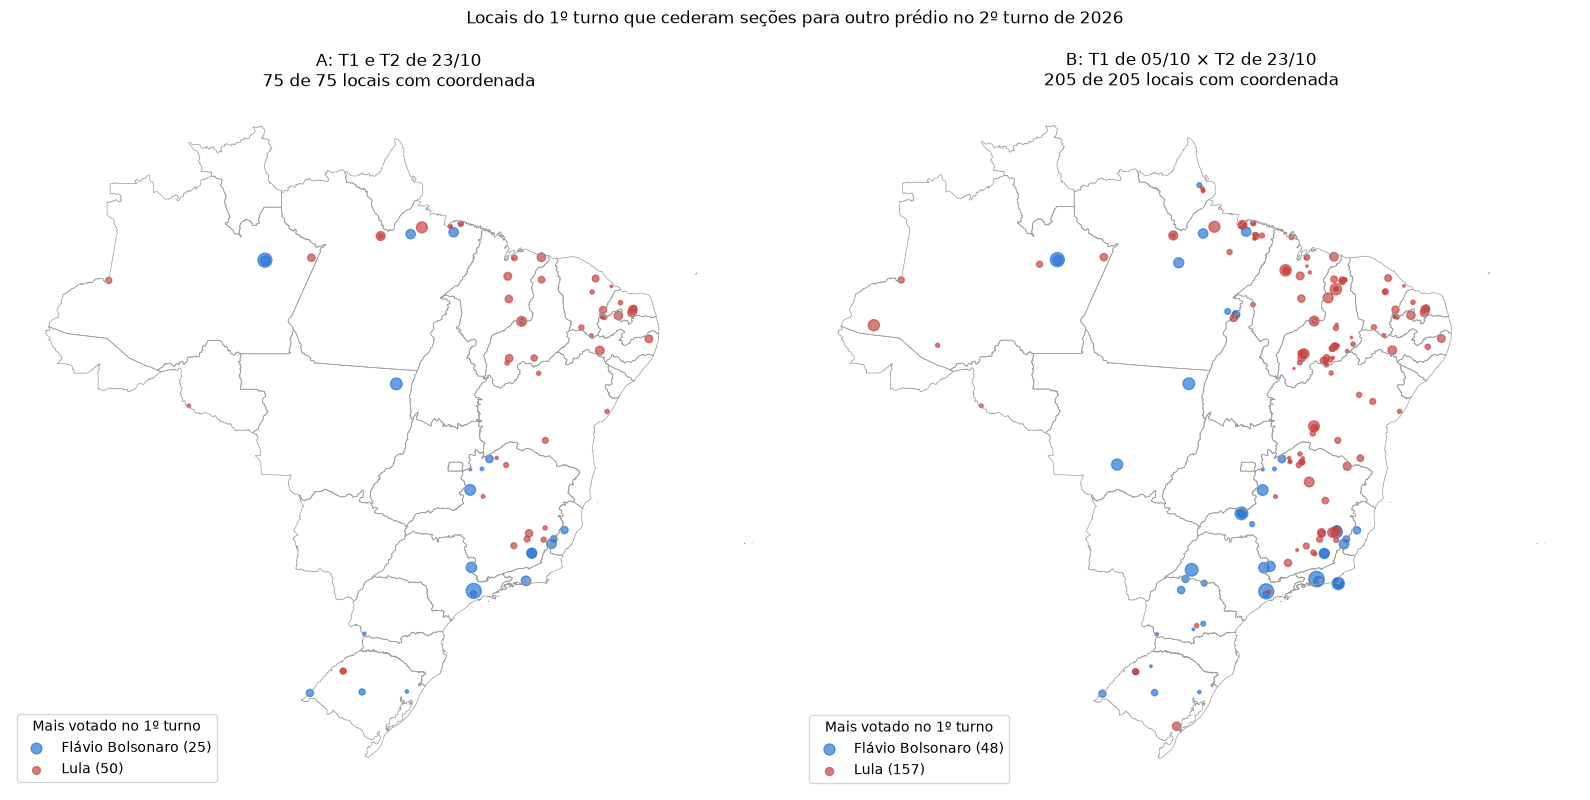

In [18]:
ufs = gpd.read_file(PROCESSADO_DIR / "aux" / "municipios.gpkg", columns=["abbrev_state"])
ufs["geometry"] = ufs.simplify(0.005)
# buffer de ida e volta fecha as frestas entre municípios que o dissolve deixa
ufs = ufs.dissolve("abbrev_state").buffer(0.01).buffer(-0.01)
fig, eixos = plt.subplots(1, 2, figsize=(16, 8))
for ax, (d, base) in zip(eixos, BASES.items()):
    sec = DEFINICOES[d]
    por_local = base.loc[base["mudou"]].groupby("local_t1")[CANDIDATOS].sum()
    por_local["vencedor"] = por_local.idxmax(axis=1).map(nomes)
    por_local["eleitores"] = sec.loc[sec["mudou"]].groupby("local_t1")["qt_eleitor_secao"].sum()
    cad_t1 = c_novo_t1 if d == DEF_A else c_antigo_t1
    pontos = gpd.GeoDataFrame(por_local, geometry=cad_t1["geometry"].reindex(por_local.index), crs=4674)
    pontos = pontos.loc[pontos.geometry.notna() & ~pontos.geometry.is_empty]
    ufs.boundary.plot(ax=ax, color="#9b9b9b", linewidth=0.5)
    for nome, grupo in pontos.groupby("vencedor"):
        grupo.plot(ax=ax, markersize=grupo["eleitores"] / 40, color=COR_CANDIDATO.get(nome, COR_OUTROS_PARTIDOS),
                   alpha=0.7, label=f"{nome} ({len(grupo)})")
    ax.legend(title="Mais votado no 1º turno", loc="lower left")
    ax.set_title(f"{d}\n{len(pontos)} de {len(por_local)} locais com coordenada")
    ax.set_axis_off()
fig.suptitle("Locais do 1º turno que cederam seções para outro prédio no 2º turno de 2026", y=1.02)
plt.tight_layout()
plt.show()

## 7. Lista de locais (1º turno → 2º turno)

In [19]:
def lista_pares(sec: pd.DataFrame, base: pd.DataFrame, cad_t2: pd.DataFrame) -> pd.DataFrame:
    votos_par = pc_validos(base.loc[base["mudou"]].groupby(["local_t1", "local_t2"])[CANDIDATOS].sum())
    pares = (
        sec.loc[sec["mudou"]]
        .groupby(["local_t1", "local_t2"])
        .agg(
            sg_uf=("sg_uf", "first"),
            nm_municipio=("nm_municipio", "first"),
            nr_zona=("nr_zona", "first"),
            nm_local_t1=("nm_local_votacao_t1", "first"),
            ds_endereco_t1=("ds_endereco_t1", "first"),
            nm_local_t2=("nm_local_votacao_t2", "first"),
            ds_endereco_t2=("ds_endereco_t2", "first"),
            dist_m=("dist_m", "first"),
            secoes=("id_secao", "size"),
            eleitores=("qt_eleitor_secao", "sum"),
        )
        .join(votos_par.rename(columns=lambda c: f"% {c}" if c != "validos" else c))
    )
    pares["local_t1_sai_do_t2"] = ~pares.index.get_level_values("local_t1").isin(cad_t2.index)
    return pares.reset_index().sort_values("eleitores", ascending=False)


PARES = {d: lista_pares(DEFINICOES[d], BASES[d], c_novo_t2) for d in DEFINICOES}
for d, p in PARES.items():
    print(f"{d}: {len(p)} pares; {p.loc[p['local_t1_sai_do_t2'], 'local_t1'].nunique()} locais do T1 "
          "não existem mais no T2")
PARES[DEF_A].head(20).round(1)

A: T1 e T2 de 23/10: 76 pares; 51 locais do T1 não existem mais no T2
B: T1 de 05/10 × T2 de 23/10: 211 pares; 148 locais do T1 não existem mais no T2


,local_t1,local_t2,sg_uf,nm_municipio,nr_zona,nm_local_t1,ds_endereco_t1,nm_local_t2,ds_endereco_t2,dist_m,secoes,eleitores,% Lula,% Flávio Bolsonaro,validos,local_t1_sai_do_t2
64,7107202561163,7107202561902,SP,SÃO PAULO,256,EE. CONSELHEIRO RUY BARBOSA,"RUA PROF. ANTÔNIO CASTELAR DE FRANCESCHI, 200",RECANTO NOSSA SENHORA DE LOURDES,"AV. LUIS CARLOS GENTILE DE LAET, 1736",564.7,12,4663,34.9,53.7,3309,True
2,0255000582011,0255000582127,AM,MANAUS,58,E. E. FRANCISCA DE PAULA DE JESUS IZABEL,"AV A, CJ FRANCISCA MENDES",ESCOLA ESTADUAL RAIO DE SOL,"ILHAS MALDIVAS, S/N - 3. NOVA CIDADE. 69097272...",NaN,11,4070,34.8,56.3,3206,True
66,7659700451848,7659700451015,PR,LARANJEIRAS DO SUL,45,PAVILHÃO DA IGREJA MATRIZ SANTANA,RUA XV DE NOVEMBRO,COLEGIO ESTADUAL PROFESSOR GILDO ALUISIO SCHUCK,R GENERAL ESPIRITO SANTO 552,NaN,12,3777,33.9,58.3,2927,True
73,9028000281104,9028000281023,MT,CONFRESA,28,EEDIEB CREUSLHI DE SOUZA RAMOS,RUA DO PÉ DE PEQUI S/N,ESCOLA MUNICIPAL TAPIRAGUAIA,RUA TAPIRAPÉ S/N,732.2,8,2832,19.5,76.5,2063,True
72,9005000081236,9005000081147,MT,ALTO ARAGUAIA,8,FACULDADE UNOPAR,RUA BENJAMIN CONSTANT,ESCOLA ESTADUAL ARLINDA PESSOA MORBECK,"AVENIDA VEREADOR LAURISTON FERNANDES, 74",NaN,9,2592,33.5,59.7,1817,True
6,0413800901015,0413800901449,PA,ANAJÁS,90,EE RUI BARBOSA,"TRAV. REZENDE JUNIOR, SN - ANAJÁS/PA",EM ROSELY PAIVA,RUA ESTRADA NOVA OLINDA,NaN,8,2463,45.7,44.6,1799,True
53,4939502031180,4939502031368,MG,PARACATU,203,E. E. OLINDINA LOUREIRO,"RUA SEVERIANO SILVA NEIVA, 1049",E. M. JOAQUIM ADJUTO BOTELHO,"RUA MARQUÊS DE POMBAL, 426",1127.7,7,2369,43.6,49.1,1533,True
63,7083101221945,7083101222054,SP,SÃO JOÃO DA BOA VISTA,122,EMEIF SARAH SALOMÃO,"R LUIZ FRANCISCO, S/N",NOVA EMEB ANTONIO SANTOS CABRAL - RESEDÁS,"RUA ALFEU DOVAL, 290",669.3,6,2245,31.6,59.0,1625,True
55,5397002751210,5397002751503,MG,UBÁ,275,E. E. DEP. CARLOS PEIXOTO FILHO (POLIVALENTE),"AV. OLEGÁRIO MACIEL, 975",ESCOLA ESTADUAL SENADOR LEVINDO COELHO,"RUA JOSÉ PEDRO CALDEIRA,390",1189.8,6,2123,40.9,49.4,1586,True
22,1089800461147,1089800461074,PI,GUADALUPE,46,CRECHE MUNICIPAL VOVÓ LOURDINHA,"AVENIDA MANOEL RIBEIRO DA FONSECA, S/N",NUCLEO DE ENSINO SUPLETIVO CARLOS FRANCO,AV. ENGENHEIRO JOSE CAVALCANTI S/N,517.0,7,1969,73.8,22.1,1405,True


## 8. Conferência

In [20]:
for d, b in BASES.items():
    tot = b[CANDIDATOS].sum()
    for nr, oficial in OFICIAL_T1.items():
        assert tot[nr] == oficial, (d, nomes[nr], tot[nr], oficial)
    assert PARES[d]["secoes"].sum() == DEFINICOES[d]["mudou"].sum()
    assert len(DEFINICOES[d]) == len(t1_novo)

# NR_LOCAL_VOTACAO_ORIGINAL das linhas do T2: aponta para o local do T1?
for d, s in DEFINICOES.items():
    m = s.loc[s["mudou"]]
    nr_original = pd.Series(t2_novo.loc[m["id_secao"], "nr_local_votacao_original"].to_numpy(), index=m.index)
    original = chave(m["cd_municipio"], m["nr_zona"], nr_original)
    print(f"{d}: local 'original' do T2 = local do T1 em {(original == m['local_t1']).sum()} de {len(m)} trocas")
print("ok")

A: T1 e T2 de 23/10: local 'original' do T2 = local do T1 em 230 de 277 trocas
B: T1 de 05/10 × T2 de 23/10: local 'original' do T2 = local do T1 em 633 de 666 trocas
ok


## 9. Saídas

In [21]:
SAIDA.mkdir(parents=True, exist_ok=True)
prefixo = "mudanca_local_turno_2026"


def junta(tabelas: dict[str, pd.DataFrame], indice: bool = False) -> pd.DataFrame:
    return pd.concat({d: t.reset_index() if indice else t for d, t in tabelas.items()}, names=["definicao"]) \
        .reset_index(level=0).reset_index(drop=True)


saidas = {
    "secoes": junta({d: s.loc[s["mudou_local"]] for d, s in DEFINICOES.items()}),
    "pares": junta(PARES),
    "resumo": junta({d: r.rename_axis("indicador") for d, r in RESUMOS.items()}, indice=True),
    "por_uf": junta(POR_UF, indice=True),
    "por_municipio": junta({d: t.loc[t["seções que mudaram"] > 0] for d, t in POR_MUN.items()}, indice=True),
}
for nome, df in saidas.items():
    df.to_parquet(SAIDA / f"{prefixo}_{nome}.parquet", index=False)
    if nome in ("pares", "por_uf", "por_municipio"):
        df.to_csv(SAIDA / f"{prefixo}_{nome}.csv", index=False, encoding="utf-8-sig")
sorted(p.name for p in SAIDA.glob(f"{prefixo}_*"))

['mudanca_local_turno_2026_pares.csv',
 'mudanca_local_turno_2026_pares.parquet',
 'mudanca_local_turno_2026_por_municipio.csv',
 'mudanca_local_turno_2026_por_municipio.parquet',
 'mudanca_local_turno_2026_por_uf.csv',
 'mudanca_local_turno_2026_por_uf.parquet',
 'mudanca_local_turno_2026_resumo.parquet',
 'mudanca_local_turno_2026_secoes.parquet']

## Conclusão

**Tamanho.** Pela definição A, 277 seções (82 mil eleitores, 0,05% do
eleitorado) trocaram de prédio entre os turnos, saindo de 76 pares de locais;
outras 70 só mudaram de número. Pela B são 666 seções (179 mil eleitores). Em
2022 tinham sido 1.387 seções com outro local, sem separar renumeração.

**1. Quem teve mais voto.** No agregado, Lula: nas seções que mudaram ele teve
51,0% dos válidos (A) ou 54,0% (B), contra 45,2% no Brasil; Flávio, 42,7% ou
40,1%, contra 47,0%. Lula foi o mais votado em 2/3 (A) a 3/4 (B) dos locais que
cederam seções, contra 53,5% de todos os locais. Mas essa diferença vem quase toda
de **onde** as mudanças aconteceram (Norte e Nordeste pesam mais do que no
eleitorado), não de quem foi mudado dentro de cada lugar: comparando com as demais
seções do mesmo município, a diferença média ponderada é −0,5 p.p. para Lula em A
(Lula melhor onde mudou em 33 de 65 municípios, Flávio em 34) e +0,8 p.p. em B
(mediana +2,0, Lula melhor em 75 de 129). Ou seja: sem viés claro em A, e um viés
pequeno a favor de Lula em B, de ordem de grandeza bem menor que a do agregado.

**2. Onde.** Em número de eleitores, Sudeste (31%), Nordeste (30%) e Norte (24%);
em proporção do eleitorado, o Norte é de 2,5 a 5 vezes mais atingido (0,15%) que as
outras regiões. Por UF (A): MG, PA, AM, SP e PI em números absolutos; AP, AM, PI,
MT e RN em proporção (0,2–0,3%). As mudanças são pontuais: quase sempre um ou dois
prédios por município, que em município pequeno atingem uma fração grande do
eleitorado (Guadalupe-PI 28%, Ibitirama-ES 26%, Alto Araguaia-MT 22%, Laranjeiras
do Sul-PR 15%). Nas capitais, Manaus (zonas 58 e 63) e São Paulo (zona 256, EE
Conselheiro Ruy Barbosa → Recanto Nossa Senhora de Lourdes, 4,7 mil eleitores). Na
definição B entram também Piauí (1% do eleitorado da UF), Arraial do Cabo e Nova
Iguaçu (RJ) e Araguari (MG).

**Ressalvas.** A escolha entre A e B depende de o arquivo de 23/10 corrigir o 1º
turno ou gravar nos dois turnos uma mudança posterior (seção 2) — vale perguntar ao
TSE ou esperar o arquivo pós-2º turno. O TSE ainda não tem coordenada para a maior
parte dos locais novos; nesses a separação entre troca de prédio e renumeração é
só pelo nome e endereço.